<a href="https://colab.research.google.com/github/KeertanPatel-CS/movie_recommender-svd/blob/main/notebooks/03_low_rank.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Movie Recommendation System
## Milestone 3: Low-Rank Prediction

**Team members:** Kirtan Patel and Rudra Patel  
**Course:** MATH 344L

In this milestone, we use Singular Value Decomposition (SVD) to find
patterns in movie ratings and predict missing ratings.

We will compare three approaches:
1. Fill missing ratings with movie averages before applying SVD.
2. Subtract the baseline first, then apply SVD to the remaining differences.
3. Repeatedly update missing values using a low-rank approximation.

We will use the same training and test split as Milestone 2 so that
our comparisons are fair.

In [2]:
import os
import sys

# Download our repository if it is not already in this Colab session.
REPO = "movie_recommender-svd"

if not os.path.exists(REPO):
    !git clone -q https://github.com/KeertanPatel-CS/movie_recommender-svd.git

# Tell Python where to find our reusable functions.
sys.path.insert(0, f"{REPO}/src")

from evaluate import split_ratings, to_matrix, rmse

# Our Milestone 2 function is named bias_baseline.
# Give it the shorter name used in the Milestone 3 handout.
from models import bias_baseline as baseline

print("Project functions imported successfully.")

Project functions imported successfully.


This cell downloads our project code from GitHub and imports the functions
we created in Milestone 2. Reusing these functions keeps our splitting
method and error calculation consistent.

Our function is named `bias_baseline` in the repository. We import it
as `baseline` to match the name used in the Milestone 3 handout.

In [3]:
import urllib.request
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Download the dataset only if the ratings file is missing.
if not os.path.exists("ml-100k/u.data"):
    urllib.request.urlretrieve(
        "https://files.grouplens.org/datasets/movielens/ml-100k.zip",
        "ml-100k.zip"
    )

    with zipfile.ZipFile("ml-100k.zip", "r") as zip_ref:
        zip_ref.extractall()

# Read the ratings into a table.
ratings = pd.read_csv(
    "ml-100k/u.data",
    sep="\t",
    names=["user", "item", "rating", "time"]
)

# Use the same seed as our main Milestone 2 comparison.
train, test = split_ratings(ratings, seed=0)

# Build the matrix using training ratings only.
R = to_matrix(train)
known = ~np.isnan(R)

# Store the hidden answers and their matrix positions.
truth = test["rating"].to_numpy()
u = test["user"].to_numpy() - 1
i = test["item"].to_numpy() - 1

print("Training ratings:", len(train))
print("Test ratings:", len(test))
print("Matrix shape:", R.shape)

Training ratings: 90032
Test ratings: 9968
Matrix shape: (943, 1682)


We load MovieLens and repeat the split from Milestone 2 using seed 0.
The training matrix contains only ratings that the models are allowed
to use. Missing entries, including hidden test ratings, are stored as NaN.

The variable `known` identifies the available training ratings.
The variables `u` and `i` locate the test entries, while `truth` stores
their actual ratings for evaluation.

In [4]:
def score(P):
    """Calculate test RMSE for a full matrix of predicted ratings."""

    # Select predictions at the hidden test positions.
    predictions = P[u, i]

    # Keep predictions within the valid rating range.
    predictions = np.clip(predictions, 1, 5)

    return rmse(predictions, truth)

Each model will produce a matrix containing predicted ratings.
The `score` function selects only the hidden test entries, clips their
predictions to the 1–5 star range, and calculates RMSE.

Lower RMSE means more accurate predictions on these test ratings.
This function evaluates predictions; it is not used to fit the baseline.

In [5]:
def baseline_matrix(R):
    """Predict ratings using the overall mean and user/movie effects."""

    # Calculate these effects using training ratings only.
    mu, b_user, b_item = baseline(R)

    # Turn user effects into a column and movie effects into a row.
    # NumPy combines them to produce one prediction for every pair.
    return mu + b_user[:, None] + b_item[None, :]


B = baseline_matrix(R)

print("Baseline matrix shape:", B.shape)
print("Baseline test RMSE:", round(score(B), 4))

Baseline matrix shape: (943, 1682)
Baseline test RMSE: 0.9545


The baseline combines the overall average rating, each user's tendency
to rate higher or lower, and each movie's remaining effect.

The matrix B contains a baseline prediction for every user and movie.
Its test RMSE should match the user + movie effects result from
Milestone 2. This is the benchmark for our SVD models.

## Low-Rank Approximation

SVD breaks a matrix into three parts: U, s, and Vt.
The values in s describe the strengths of different patterns.

A rank-k approximation keeps only the k strongest SVD components.
A smaller k gives a simpler approximation.

This gives the best rank-k approximation to the filled matrix in
squared-error terms. However, it does not guarantee the best predictions
for missing ratings, so we still need to measure test RMSE.

In [6]:
def rank_k(U, s, Vt, k):
    """Rebuild a matrix using its first k SVD components."""

    # Keep the first k columns of U and rows of Vt.
    # Put the first k singular values on a diagonal matrix.
    return U[:, :k] @ np.diag(s[:k]) @ Vt[:k, :]

The function keeps the first k SVD components and multiplies them
together to rebuild an approximate matrix. The @ symbol means matrix
multiplication.

We can compute an SVD once and reuse it to try several values of k.

## Model 1: Fill Missing Ratings with Movie Averages

SVD cannot work directly with NaN entries. Our first approach fills each
missing entry with that movie's average training rating.

We keep the observed training ratings unchanged.

In [7]:
# Calculate the overall training average as a fallback.
mu = np.nanmean(R)

# Count the available training ratings for each movie.
n_item = known.sum(axis=0)

# Start every movie's average at the overall average.
item_mean = np.full(R.shape[1], mu)
has_rating = n_item > 0

# Calculate movie averages using only observed training ratings.
item_mean[has_rating] = (
    np.nansum(R, axis=0)[has_rating] / n_item[has_rating]
)

# Keep known ratings and fill gaps with movie averages.
F = np.where(known, R, item_mean[None, :])

# Compute the SVD of the completed matrix.
U1, s1, Vt1 = np.linalg.svd(F, full_matrices=False)

print("Model 1 SVD complete.")
print("Missing entries remaining:", np.isnan(F).sum())

Model 1 SVD complete.
Missing entries remaining: 0


The matrix F contains the known training ratings and movie-average
guesses for every missing entry. It has no NaN values, so we can compute
its SVD.

The filled values are temporary guesses, not actual ratings.
Because most entries are missing, these guesses can strongly influence
the patterns that SVD finds.

## Model 2: Subtract the Baseline First

The baseline already accounts for users who usually rate higher or lower
and movies that tend to receive higher or lower ratings.

We subtract the baseline and use SVD to approximate the remaining
differences. These differences are called residuals.

In [8]:
# For known ratings, calculate the difference from the baseline.
# For missing ratings, start with a residual of zero.
X = np.where(known, R - B, 0.0)

# Compute the SVD of the residual matrix.
U2, s2, Vt2 = np.linalg.svd(X, full_matrices=False)

print("Model 2 SVD complete.")

Model 2 SVD complete.


A positive residual means a user rated a movie higher than the baseline
predicted. A negative residual means the rating was lower.

For missing entries, zero means we initially predict no difference from
the baseline. It does not mean a zero-star rating.

After approximating the residuals, we must add B back to return to
the original star-rating scale.

In [9]:
# Try the ranks listed in the handout.
ks = [1, 2, 3, 5, 10, 15, 20, 30, 50, 100, 200, 400, 943]

err1 = []
err2 = []

for k in ks:
    # Model 1 directly approximates the filled ratings.
    P1 = rank_k(U1, s1, Vt1, k)

    # Model 2 approximates residuals, then adds the baseline back.
    P2 = rank_k(U2, s2, Vt2, k) + B

    # Evaluate both models on the same hidden test ratings.
    err1.append(score(P1))
    err2.append(score(P2))

    print(
        f"k = {k:3d} | "
        f"Model 1: {err1[-1]:.4f} | "
        f"Model 2: {err2[-1]:.4f}"
    )

k =   1 | Model 1: 1.0060 | Model 2: 0.9428
k =   2 | Model 1: 0.9917 | Model 2: 0.9368
k =   3 | Model 1: 0.9884 | Model 2: 0.9356
k =   5 | Model 1: 0.9790 | Model 2: 0.9304
k =  10 | Model 1: 0.9726 | Model 2: 0.9256
k =  15 | Model 1: 0.9742 | Model 2: 0.9250
k =  20 | Model 1: 0.9745 | Model 2: 0.9261
k =  30 | Model 1: 0.9763 | Model 2: 0.9300
k =  50 | Model 1: 0.9876 | Model 2: 0.9363
k = 100 | Model 1: 1.0048 | Model 2: 0.9453
k = 200 | Model 1: 1.0168 | Model 2: 0.9500
k = 400 | Model 1: 1.0273 | Model 2: 0.9543
k = 943 | Model 1: 1.0284 | Model 2: 0.9545


We compare both models at several ranks using the same test ratings.
Lower test RMSE indicates more accurate predictions.

At full rank, Model 1 reconstructs its movie-average-filled matrix.
Model 2 reconstructs its residual matrix, whose missing entries were
zero, so its test predictions return to the baseline.

This comparison is exploratory. In Exercise 4, we will use a separate
validation set to choose k without using the test ratings.

## Comparing Test Error Across Ranks

We plot the test RMSE for both models against rank k.
The horizontal baseline shows whether the SVD models improve on
our Milestone 2 predictions.

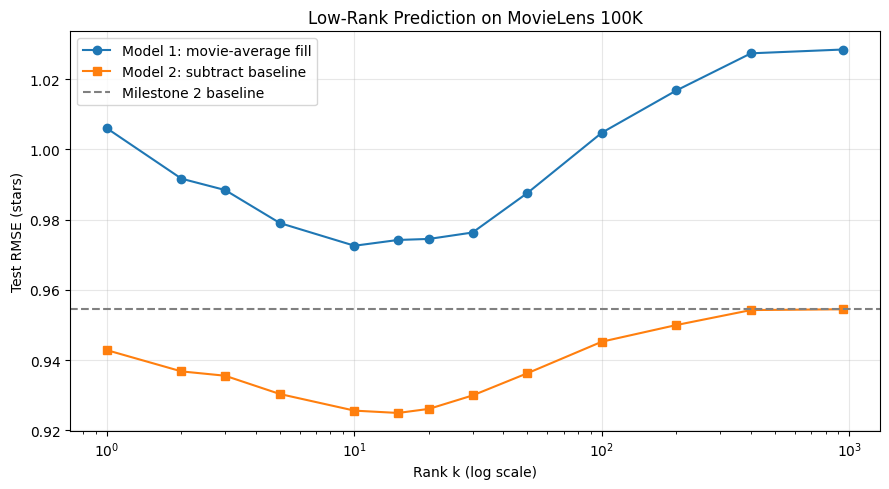

In [10]:
# Start a new figure.
plt.figure(figsize=(9, 5))

# Use a logarithmic horizontal axis because the ranks vary widely.
plt.semilogx(ks, err1, "o-", label="Model 1: movie-average fill")
plt.semilogx(ks, err2, "s-", label="Model 2: subtract baseline")

# Show the Milestone 2 baseline for comparison.
plt.axhline(
    score(B),
    color="gray",
    linestyle="--",
    label="Milestone 2 baseline"
)

# Label the graph.
plt.xlabel("Rank k (log scale)")
plt.ylabel("Test RMSE (stars)")
plt.title("Low-Rank Prediction on MovieLens 100K")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

# Save the graph before displaying it.
plt.savefig("rmse_vs_k.png", dpi=150)
plt.show()

### Results

Model 1 had its lowest test RMSE of approximately 0.9726 at k = 10.
It did not beat the baseline RMSE of 0.9545. Most entries in the
filled matrix are movie-average guesses, which strongly influence
the approximation.

Model 2 performed better after subtracting the baseline. Its lowest
test RMSE was approximately 0.9250 at k = 15, about a 3.1% reduction
from the baseline.

Both models initially improve as k increases, but their errors later
rise. Keeping more components does not necessarily improve predictions:
the approximation increasingly reproduces the filled matrix, including
its temporary guesses.

At full rank, Model 1 returns the movie-average RMSE of 1.0284.
Model 2 returns the baseline RMSE of 0.9545. These match our
Milestone 2 results.

These best ranks were identified using the test set, so this comparison
is exploratory. We will choose a rank using validation data in Exercise 4.


## Model 3: Iterative SVD Imputation

Model 2 starts missing residuals at zero and computes one approximation.
Model 3 uses that approximation to update the missing residuals,
then computes another approximation.

We repeat this process 15 times. After each round, we restore the
observed training residuals and update only the missing entries.
The hidden test ratings are never used to fill the gaps.

In [11]:
def iterative_svd_predict(R, k, n_iter=15):
    """Predict ratings by repeatedly updating missing residuals."""

    # Identify observed training ratings.
    known = ~np.isnan(R)

    # Calculate the baseline using only the supplied ratings.
    B = baseline_matrix(R)

    # Start missing residuals at zero.
    X = np.where(known, R - B, 0.0)

    for step in range(n_iter):
        # Find a rank-k approximation of the current residual matrix.
        U, s, Vt = np.linalg.svd(X, full_matrices=False)
        L = rank_k(U, s, Vt, k)

        # Restore observed residuals and refill only the gaps.
        X = np.where(known, R - B, L)

    # Add the baseline back to return predictions to the star scale.
    return L + B

The function starts with the same residual matrix as Model 2.
Each round produces a low-rank approximation called L.

The next round uses the original residuals at observed positions
and the new estimates at missing positions. Finally, we add the
baseline back to obtain predicted star ratings.

The function returns the final low-rank prediction plus the baseline.
We clip predictions to 1–5 when displaying or scoring them.

### Try Model 3 on the Toy Matrix

First, we use the small matrix from Milestone 1.
We keep the same user names used in our first notebook.

With k = 1, we check whether one component captures the main
action-versus-romance preference pattern.

In [12]:
# Use the same ratings and user names as our Milestone 1 notebook.
toy = np.array([
    [5, 4, 5, 1, np.nan, 2],
    [4, np.nan, 5, 2, 1, 1],
    [5, 5, np.nan, 1, 2, np.nan],
    [1, 2, 1, 5, 4, np.nan],
    [np.nan, 1, 2, 4, 5, 5],
    [2, 1, np.nan, 5, np.nan, 4]
])

users = ["Josh", "Anna", "Simon", "Ethan", "Tobi", "Rose"]
movies = [
    "Action 1", "Action 2", "Action 3",
    "Romance 1", "Romance 2", "Romance 3"
]

# Calculate baseline and iterative predictions.
B_toy = baseline_matrix(toy)
P_toy = np.clip(iterative_svd_predict(toy, k=1), 1, 5)

# Display predictions only for the eight missing ratings.
for row, col in np.argwhere(np.isnan(toy)):
    print(
        f"{users[row]:6s} | {movies[col]:10s} | "
        f"Baseline: {B_toy[row, col]:.1f} | "
        f"Model 3: {P_toy[row, col]:.1f}"
    )

Josh   | Romance 2  | Baseline: 3.4 | Model 3: 2.1
Anna   | Action 2   | Baseline: 2.1 | Model 3: 3.2
Simon  | Action 3   | Baseline: 3.5 | Model 3: 5.0
Simon  | Romance 3  | Baseline: 3.1 | Model 3: 1.4
Ethan  | Romance 3  | Baseline: 2.5 | Model 3: 4.0
Tobi   | Action 1   | Baseline: 3.8 | Model 3: 2.6
Rose   | Action 3   | Baseline: 3.2 | Model 3: 1.4
Rose   | Romance 2  | Baseline: 3.0 | Model 3: 4.5


This comparison shows how the baseline and Model 3 predict the eight
missing ratings. The baseline uses overall user and movie effects,
while Model 3 can also capture patterns in individual preferences.

We can compare these predictions with our guesses from Milestone 1.
However, those guesses are not known answers, so this example checks
whether the predictions seem reasonable rather than measuring accuracy.

In [13]:
# Try four ranks on the full MovieLens training matrix.
ks3 = [2, 5, 10, 20]
err3 = []

for k in ks3:
    # Each call performs 15 SVD rounds.
    P3 = iterative_svd_predict(R, k, n_iter=15)

    # Score the predictions on the same test set as the other models.
    model3_error = score(P3)
    err3.append(model3_error)

    print(f"k = {k:2d} | Model 3 test RMSE: {model3_error:.4f}")

k =  2 | Model 3 test RMSE: 0.9291
k =  5 | Model 3 test RMSE: 0.9206
k = 10 | Model 3 test RMSE: 0.9347
k = 20 | Model 3 test RMSE: 0.9780


We test Model 3 at four ranks, using 15 rounds for each rank.
Every result uses the same hidden test ratings as the earlier models.

Repeated updates may improve the predictions, but larger ranks and
more rounds do not guarantee better results. We compare the measured
errors before deciding which settings worked best in this experiment.

### Model 3 Results

On the toy matrix, Model 3 captures the action-versus-romance pattern.
For example, it predicts 5.0 for Simon on Action 3 and 1.4 on Romance 3.
These predictions agree with the direction of our Milestone 1 guesses,
although they do not always match our guessed ratings exactly.

On MovieLens, Model 3 produced these test RMSE values:

| Rank k | Test RMSE |
|---|---|
| 2 | 0.9291 |
| 5 | 0.9206 |
| 10 | 0.9347 |
| 20 | 0.9780 |

The best rank tested was k = 5, with RMSE 0.9206. This is approximately
3.6% lower than the baseline RMSE of 0.9545 and slightly better than
Model 2's best result of 0.9250.

Increasing the rank beyond 5 made the test predictions worse in this
experiment. At k = 20, Model 3 was worse than the baseline.
This shows that a more detailed approximation does not necessarily
generalize better to hidden ratings.

These comparisons are exploratory because we inspected test scores
at several ranks.

## Exercises

### Exercise 1: How Much Does the Fill Matter?

We compare three ways to fill missing ratings before applying SVD:
movie averages, 3 stars, and 0 stars.

We test each fill at k = 5, 10, and 20 using the same training and
test ratings. Only the fill method changes.

In [14]:
# Compare the fill methods at the three requested ranks.
exercise_ks = [5, 10, 20]
fill_results = []

# Reuse the movie-average SVD from Model 1.
for k in exercise_ks:
    prediction = rank_k(U1, s1, Vt1, k)

    fill_results.append({
        "Fill": "Movie average",
        "Rank": k,
        "Test RMSE": score(prediction)
    })

# Try filling missing ratings with 3 stars and then 0 stars.
for fill_value in [3.0, 0.0]:
    # Keep observed training ratings unchanged.
    filled = np.where(known, R, fill_value)

    # Compute one SVD for this fill method.
    U_fill, s_fill, Vt_fill = np.linalg.svd(
        filled, full_matrices=False
    )

    for k in exercise_ks:
        prediction = rank_k(U_fill, s_fill, Vt_fill, k)

        fill_results.append({
            "Fill": f"{fill_value:.0f} stars",
            "Rank": k,
            "Test RMSE": score(prediction)
        })

# Arrange the results so the fill methods are easy to compare.
fill_table = pd.DataFrame(fill_results).pivot(
    index="Rank",
    columns="Fill",
    values="Test RMSE"
)

print(fill_table.round(4))

Fill  0 stars  3 stars  Movie average
Rank                                 
5      2.3357   1.0697         0.9790
10     2.2659   1.0533         0.9726
20     2.2650   1.0554         0.9745


The code compares low-rank predictions made with three different fills.
All averages are calculated from training ratings only, and all
predictions are evaluated on the same test set.

Filling missing entries with zero treats unknown ratings as zero-star
ratings. About 94% of the training matrix is missing, so these artificial
zeros dominate the matrix that SVD approximates. Clipping predictions
to the 1–5 range afterward does not undo this effect.

At all three tested ranks, the ranking from best to worst was:
movie-average fill, 3-star fill, then zero fill.

For example, at k = 10, movie-average filling gave RMSE 0.9726,
compared with 1.0533 for 3-star filling and 2.2659 for zero filling.
This shows that the initial fill has a large effect on prediction quality.

### Exercise 2: Why Does Full Rank Give Back the Baseline?

At k = 943, we keep all the SVD components. This reconstructs the
original residual matrix, apart from small numerical rounding errors.

In Model 2, the missing residuals were initially filled with zero.
At full rank, those entries remain zero. Adding the baseline B back
therefore gives the baseline prediction at every missing position.
This explains why the test RMSE returns to 0.9545.

The entire prediction matrix does not equal B: at observed training
positions, it reconstructs the original ratings.

Model 3 also predicts the baseline at missing positions when used
at full rank. The first round reconstructs the starting residual
matrix, so the missing residuals stay zero. Refilling the gaps changes
nothing, and later rounds repeat the same result.

Full rank therefore gives no improvement over the baseline for
missing ratings. A lower rank is needed to transfer patterns from
observed ratings into the missing positions.

### Exercise 3: How Many Rounds?

We record test RMSE after each round of iterative SVD for k = 2
and k = 10. We use 30 rounds to compare the original choice of
15 rounds with earlier and later stopping points.

The scores are recorded for comparison only. They do not affect
how the missing values are updated.

In [15]:
def iterative_svd_history(R, k, n_iter=30):
    """Record test error after each round of iterative SVD."""

    # Build the baseline and starting residuals from training data.
    known = ~np.isnan(R)
    B = baseline_matrix(R)
    X = np.where(known, R - B, 0.0)
    errors = []

    for step in range(n_iter):
        # Approximate the current residual matrix.
        U, s, Vt = np.linalg.svd(X, full_matrices=False)
        L = rank_k(U, s, Vt, k)

        # Record test error without using it to update the matrix.
        errors.append(score(L + B))

        # Keep observed residuals fixed and update only the gaps.
        X = np.where(known, R - B, L)

    return errors


history_2 = iterative_svd_history(R, k=2)
history_10 = iterative_svd_history(R, k=10)

for k, errors in [(2, history_2), (10, history_10)]:
    best_round = int(np.argmin(errors)) + 1

    print(f"k = {k}")
    print(f"  Best round tested: {best_round}")
    print(f"  Lowest test RMSE: {min(errors):.4f}")
    print(f"  Round 15 RMSE: {errors[14]:.4f}")
    print(f"  Round 30 RMSE: {errors[29]:.4f}")

k = 2
  Best round tested: 8
  Lowest test RMSE: 0.9285
  Round 15 RMSE: 0.9291
  Round 30 RMSE: 0.9304
k = 10
  Best round tested: 3
  Lowest test RMSE: 0.9188
  Round 15 RMSE: 0.9347
  Round 30 RMSE: 0.9482


The function follows the same update process as Model 3 but stores
an error score after each round. We compare the lowest observed error
with the errors at rounds 15 and 30.

These results are exploratory because we inspect test errors.
A final stopping rule should be selected using validation data.

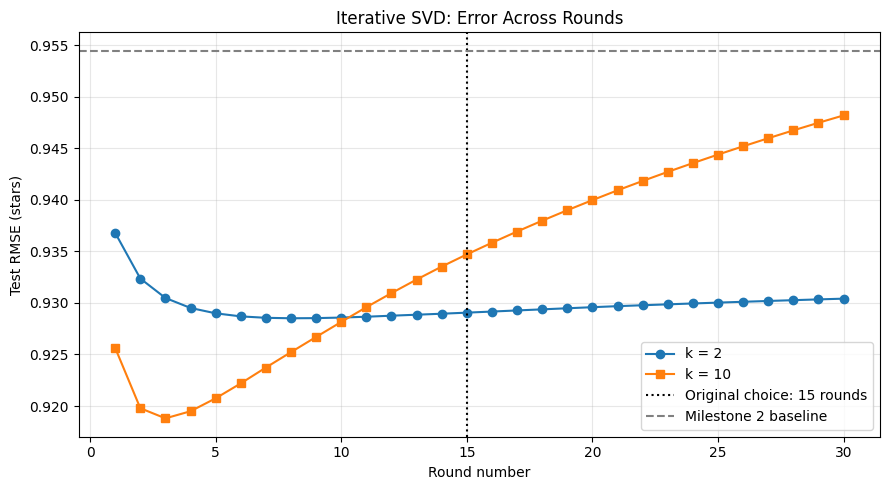

In [16]:
# Plot how test error changes over the 30 rounds.
rounds = np.arange(1, 31)

plt.figure(figsize=(9, 5))
plt.plot(rounds, history_2, "o-", label="k = 2")
plt.plot(rounds, history_10, "s-", label="k = 10")

plt.axvline(
    15, color="black", linestyle=":",
    label="Original choice: 15 rounds"
)
plt.axhline(
    score(B), color="gray", linestyle="--",
    label="Milestone 2 baseline"
)

plt.xlabel("Round number")
plt.ylabel("Test RMSE (stars)")
plt.title("Iterative SVD: Error Across Rounds")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("rmse_vs_rounds.png", dpi=150)
plt.show()

### Exercise 3 Results

For k = 2, the lowest test RMSE was 0.9285 at round 8.
At round 15, it was 0.9291, so 15 rounds was reasonably close
to the best result, although it required extra computation.

For k = 10, the lowest test RMSE was 0.9188 at round 3.
The error increased to 0.9347 at round 15 and 0.9482 at round 30.
Therefore, 15 rounds was too many for this rank in our experiment.

The k = 10 curve falls and then rises, resembling the earlier
error-versus-rank curves. This suggests overfitting: more updates
do not necessarily improve predictions on hidden ratings.

We should use validation data to choose a stopping point rather
than choosing it from these test results.

### Exercise 4: Choosing Rank with Validation Data

Earlier, we compared ranks using test RMSE. Choosing the best rank
from those results lets the test set influence our model choice.

We now split the original training ratings into a fitting set and
a validation set. We build Model 2 using only the fitting set and
choose k using validation RMSE.

After choosing k, we rebuild the model using all the original
training ratings and evaluate it on the original test set.

In [17]:
# Split only the original training ratings.
# The original test ratings are not used here.
fit, val = split_ratings(train, seed=1)

R_fit = to_matrix(fit)
known_fit = ~np.isnan(R_fit)

# Calculate the baseline using fitting ratings only.
B_fit = baseline_matrix(R_fit)

# Build and decompose the fitting residual matrix.
X_fit = np.where(known_fit, R_fit - B_fit, 0.0)
U_fit, s_fit, Vt_fit = np.linalg.svd(
    X_fit, full_matrices=False
)

# Locate the validation ratings.
val_truth = val["rating"].to_numpy()
val_u = val["user"].to_numpy() - 1
val_i = val["item"].to_numpy() - 1

validation_errors = []

# Use the same candidate ranks as the earlier comparison.
for k in ks:
    P_val = rank_k(U_fit, s_fit, Vt_fit, k) + B_fit

    # Score on validation data, not the original test data.
    val_predictions = np.clip(P_val[val_u, val_i], 1, 5)
    validation_errors.append(rmse(val_predictions, val_truth))

validation_results = pd.DataFrame({
    "Rank": ks,
    "Validation RMSE": validation_errors
})

print(validation_results.round(4).to_string(index=False))

# Select the rank with the lowest validation error.
chosen_k = ks[int(np.argmin(validation_errors))]
print("\nValidation-selected rank:", chosen_k)

 Rank  Validation RMSE
    1           0.9632
    2           0.9570
    3           0.9558
    5           0.9526
   10           0.9511
   15           0.9492
   20           0.9504
   30           0.9572
   50           0.9583
  100           0.9680
  200           0.9731
  400           0.9731
  943           0.9731

Validation-selected rank: 15


All averages and SVD components in this step come from the fitting
ratings only. The validation ratings are used to compare ranks.

We select the rank with the lowest validation RMSE, without using
the original test scores in this selection.

In [18]:
# Rebuild Model 2 using all the original training ratings.
B_final = baseline_matrix(R)
X_final = np.where(known, R - B_final, 0.0)

U_final, s_final, Vt_final = np.linalg.svd(
    X_final, full_matrices=False
)

P_final = rank_k(
    U_final, s_final, Vt_final, chosen_k
) + B_final

# Evaluate the selected model on the original test set.
selected_test_rmse = score(P_final)

# Compare with our earlier exploratory selection.
earlier_k = ks[int(np.argmin(err2))]

print("Earlier test-selected rank:", earlier_k)
print("Validation-selected rank:", chosen_k)
print(f"Selected model test RMSE: {selected_test_rmse:.4f}")
print(f"Earlier best test RMSE: {min(err2):.4f}")

# The handout uses a different example result.
print(
    "Difference from handout's 0.9332:",
    f"{selected_test_rmse - 0.9332:+.4f}"
)

Earlier test-selected rank: 15
Validation-selected rank: 15
Selected model test RMSE: 0.9250
Earlier best test RMSE: 0.9250
Difference from handout's 0.9332: -0.0082


After selecting k, we fit Model 2 again using all the original
training ratings. This allows the model to use the ratings that
were temporarily held out for validation.

The printed difference compares our result with the handout's
0.9332: a negative difference means our RMSE is lower, and a
positive difference means it is higher. Because our original split
differs from the handout's example, this is not a controlled comparison
of the two selection methods.

This procedure keeps test ratings out of this rank-selection step.
However, we already inspected the test set in earlier exercises.
A completely fresh final evaluation would require an untouched
holdout set.

### Exercise 4 Results

Validation selected k = 15, with validation RMSE approximately 0.9492.
This was the same rank selected in our earlier exploratory test comparison.

After rebuilding Model 2 using all the original training ratings,
the test RMSE was 0.9250. It matches our earlier result because
both procedures selected the same rank and used the same final
training data.

Our test RMSE is 0.0082 lower than the handout's example of 0.9332.
However, our split differs from the handout's example, so this
difference does not show that validation itself improved accuracy.
The benefit is that validation kept the test ratings out of this
rank-selection step.

### Exercise 5: Is It Luck?

We repeat the baseline and Model 2 comparison using seed 1 for the
outer train/test split.

We keep the rank selected in Exercise 4 fixed. We do not choose
another rank based on the new test results.

In [19]:
# Make a second train/test split.
train_seed1, test_seed1 = split_ratings(ratings, seed=1)

R_seed1 = to_matrix(train_seed1)
known_seed1 = ~np.isnan(R_seed1)

# Fit the baseline and Model 2 using the new training data.
B_seed1 = baseline_matrix(R_seed1)
X_seed1 = np.where(
    known_seed1, R_seed1 - B_seed1, 0.0
)

U_seed1, s_seed1, Vt_seed1 = np.linalg.svd(
    X_seed1, full_matrices=False
)

P_seed1 = rank_k(
    U_seed1, s_seed1, Vt_seed1, chosen_k
) + B_seed1

# Locate the new test ratings.
truth_seed1 = test_seed1["rating"].to_numpy()
u_seed1 = test_seed1["user"].to_numpy() - 1
i_seed1 = test_seed1["item"].to_numpy() - 1

# Evaluate both methods on the same new test set.
baseline_seed1 = rmse(
    np.clip(B_seed1[u_seed1, i_seed1], 1, 5),
    truth_seed1
)

model2_seed1 = rmse(
    np.clip(P_seed1[u_seed1, i_seed1], 1, 5),
    truth_seed1
)

# Compare with seed 0 at the same selected rank.
baseline_seed0 = score(B)

seed_comparison = pd.DataFrame({
    "Seed": [0, 1],
    "Baseline RMSE": [baseline_seed0, baseline_seed1],
    "Model 2 RMSE": [selected_test_rmse, model2_seed1]
})

seed_comparison["RMSE reduction"] = (
    seed_comparison["Baseline RMSE"]
    - seed_comparison["Model 2 RMSE"]
)

seed_comparison["Reduction (%)"] = (
    100 * seed_comparison["RMSE reduction"]
    / seed_comparison["Baseline RMSE"]
)

print("Fixed rank:", chosen_k)
print(seed_comparison.round(4).to_string(index=False))

# Compare improvement with the size of the changes between splits.
print(
    "\nBaseline RMSE change between seeds:",
    f"{abs(baseline_seed1 - baseline_seed0):.4f}"
)
print(
    "Model 2 RMSE change between seeds:",
    f"{abs(model2_seed1 - selected_test_rmse):.4f}"
)

Fixed rank: 15
 Seed  Baseline RMSE  Model 2 RMSE  RMSE reduction  Reduction (%)
    0         0.9545        0.9250          0.0295         3.0917
    1         0.9577        0.9279          0.0298         3.1091

Baseline RMSE change between seeds: 0.0032
Model 2 RMSE change between seeds: 0.0029


Within each split, both methods use the same training and test ratings.
A positive RMSE reduction means Model 2 beats the baseline.

We compare the improvement within each split with the change in
scores between splits. Two splits provide a useful stability check,
but they do not establish statistical significance or guarantee that
the model will always win.

### Exercise 5 Results

With k fixed at 15, Model 2 beat the baseline on both splits.

For seed 0, RMSE decreased from 0.9545 to 0.9250, an improvement
of approximately 3.09%.

For seed 1, RMSE decreased from 0.9577 to 0.9279, an improvement
of approximately 3.11%.

The improvement within each split was about 0.030 stars of RMSE.
By comparison, changing the seed changed the baseline RMSE by
about 0.0032 and Model 2's RMSE by about 0.0029.

The improvement was therefore roughly ten times the observed
between-seed change. This supports the conclusion that Model 2's
advantage is reasonably stable across these two splits, although
two splits are not enough to guarantee the same result every time.

### Exercise 6: What Does 0.93 Mean?

A test RMSE of 0.93 stars means the predictions have an error scale
of roughly one star on ratings hidden during training, with larger
mistakes receiving more weight. It does not mean every prediction
is within 0.93 stars of the user's actual rating.